# Ancient Environmental Metagenomics (AEMG01)
## Day 5 · Part 2: De-novo metagenome assembly and authentication of assembled contigs

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day5_Assembly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisites:** `Day1_setup.ipynb`, `Day1_QC.ipynb` (trimmed and human-free reads of sample10) and, for the comparison in Section 6, `Day2_TaxonomicProfiling.ipynb`.

### Learning outcomes
After this practical you will be able to:

* explain how **de Bruijn graph** assemblers build contigs, and why ancient DNA is hard to assemble,
* assemble a metagenome with **MEGAHIT** and choose its key options,
* compute and interpret assembly statistics – **N50, L50**, contig length distribution – with **calN50** and by hand,
* quantify the **abundance and coverage** of contigs by aligning reads back to them,
* assign **taxonomy** to contigs with **Kraken2** and compare it with read-based profiling,
* test contigs for **ancient DNA damage** with **pyDamage**, and look at them in **IGV**.

<p align="center">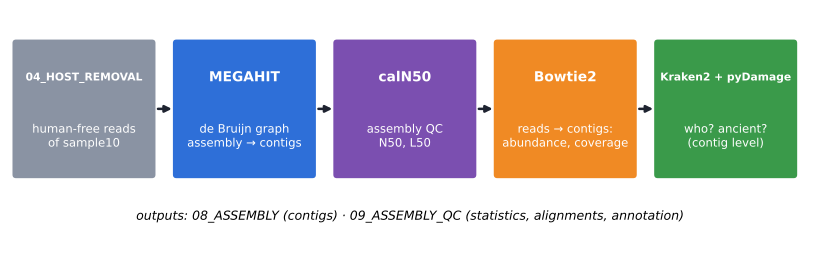<br><em>Today's workflow.</em></p>

---
## Scientific background: reference-free discovery

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/metagenomic_approaches.png" width="680"><br><em>Alignment and k-mer classification compare reads with known genomes; de-novo assembly reconstructs sequences without any reference.</em></p>

All week we compared reads with **reference genomes** – by alignment or by k-mers. That assumes the ancient organism resembles something in our database, which may not hold for very old, extinct or diverged organisms, or for the many environmental microbes never sequenced. **De-novo assembly** reconstructs longer sequences (**contigs**) directly from overlaps between reads, **without any reference**. Contigs can then be annotated, compared with databases, binned into genomes (MAGs) and authenticated.

### How a de Bruijn graph assembler works

<p align="center">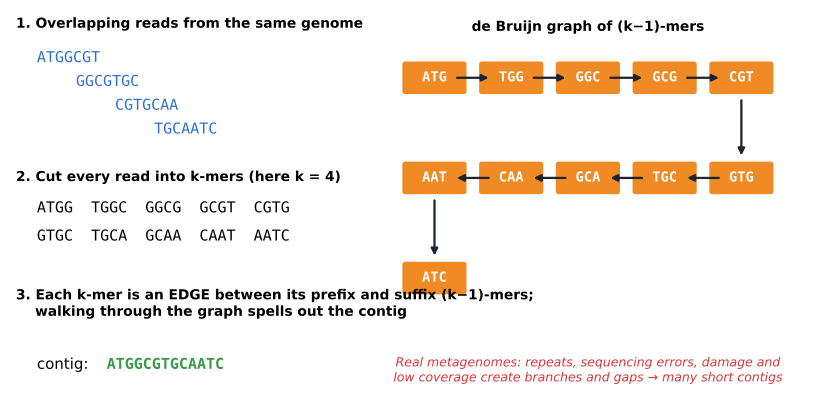<br><em>Reads → k-mers → de Bruijn graph → contig.</em></p>

Modern short-read assemblers do not compare every read with every other read (far too slow for millions of reads). Instead they:

1. cut all reads into **k-mers**,
2. build a **de Bruijn graph**: nodes are (k−1)-mers, and every k-mer is an edge from its prefix to its suffix,
3. clean the graph (remove tips and bubbles caused by sequencing errors; drop k-mers seen only once),
4. report the unbranched paths through the graph as **contigs**.

The choice of **k** is a trade-off: small k connects reads even with short overlaps (good for low coverage) but cannot resolve repeats; large k resolves repeats but needs long, error-free overlaps. **MEGAHIT** therefore assembles **iteratively** with a list of increasing k values (by default 21, 29, 39, 59, 79, 99, 119, 141), using the contigs from each round to build the next graph.

### Why ancient DNA is hard to assemble

| aDNA property | Consequence for assembly |
|---|---|
| **short fragments** (30–70 bp) | large k-mers (59, 79, …) cannot be used at all – a 45 bp read contains no 59-mer |
| **low coverage** of each organism | many genome regions are covered by one read or none → the graph breaks into short pieces |
| **damage** (C→T at read ends) | damaged positions look like sequencing errors and create bubbles/tips in the graph |
| **many organisms, uneven abundance** | only the most abundant organisms reach enough coverage to assemble |

So expect **few and short contigs** from a simulated low-coverage ancient sample – that is a realistic result, not a failure. Assembly becomes powerful for ancient samples with very high endogenous content, such as dental calculus, and with deep sequencing.

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:12
🔁 Restarting kernel...


In [ ]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

Python : /usr/bin/python3.real
mamba  : /usr/local/bin/mamba
2.5.0


### 1.2 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.3 Install today's software

| Tool | Used for | Installed |
|---|---|---|
| [MEGAHIT](https://github.com/voutcn/megahit) | de-novo assembly | base environment (Bioconda) |
| Bowtie2, samtools | aligning reads back to the contigs | base environment |
| [Kraken2](https://github.com/DerrickWood/kraken2) | taxonomic annotation of contigs | base environment |
| [pyDamage](https://github.com/maxibor/pydamage) | damage test per contig | own environment `pydamage` (as on Day 3) |
| igv-notebook | IGV inside the notebook | pip |
| **k8** + **calN50.js** | assembly statistics (N50, L50) | downloaded in the next step |

Logs go to `/content/install_*.log`.

In [ ]:
!mamba install -y -q -c conda-forge -c bioconda megahit bowtie2 samtools kraken2 pandas bzip2 > /content/install_base.log 2>&1
!mamba create -y -q -n pydamage -c conda-forge -c bioconda pydamage > /content/install_pydamage.log 2>&1
!pip install -q igv-notebook
print("done")

done


### 1.4 Download calN50 and the k8 JavaScript shell

[**calN50**](https://github.com/lh3/calN50) (by Heng Li, the author of BWA and samtools) is a tiny script that computes assembly statistics. It is written in **JavaScript**, and runs with **k8**, a small, fast JavaScript shell for the command line (it can also run with `node`).

| Command | Meaning |
|---|---|
| `wget https://raw.githubusercontent.com/lh3/calN50/master/calN50.js` | download the script (a single text file) |
| `wget -O- <url>` | download a file and write it to the **standard output** (`-O-`) instead of to disk … |
| `\| tar -jxf -` | … and unpack it on the fly: `-j` bzip2 compression (`.tar.bz2`), `-x` extract, `-f -` read the archive from the pipe |

The archive contains the folder `k8-1.2/` with ready-to-run binaries for several systems; Colab is a Linux x86-64 machine, so we use `k8-x86_64-Linux`. We keep the tools on the local disk in `/content/tools`, where files can be executed (unlike Google Drive).

In [ ]:
%%bash
mkdir -p /content/tools && cd /content/tools
[ -f calN50.js ] || wget -q https://raw.githubusercontent.com/lh3/calN50/master/calN50.js
[ -d k8-1.2 ]    || wget -q -O- https://github.com/attractivechaos/k8/releases/download/v1.2/k8-1.2.tar.bz2 | tar -jxf -
ls -lh /content/tools /content/tools/k8-1.2
/content/tools/k8-1.2/k8-x86_64-Linux -e 'print("k8 works")'

/content/tools:
total 12K
-rw-r--r-- 1 root  root    4.8K Nov 23 12:33 calN50.js
drwxr-xr-x 4 54818 1048853 4.0K May 27  2024 k8-1.2

/content/tools/k8-1.2:
total 54M
-rwxr-xr-x 1 54818 1048853  27M May 27  2024 k8-arm64-Darwin
-rw-r--r-- 1 54818 1048853  37K May 27  2024 k8.cc
-rwxr-xr-x 1 54818 1048853  28M May 27  2024 k8-x86_64-Linux
-rw-r--r-- 1 54818 1048853 1.2K Aug 10  2023 LICENSE.txt
-rw-r--r-- 1 54818 1048853  839 May 27  2024 Makefile
-rw-r--r-- 1 54818 1048853 2.3K May 27  2024 NEWS.md
-rw-r--r-- 1 54818 1048853 6.0K May 27  2024 README.md
drwxr-xr-x 2 54818 1048853 4.0K May 26  2024 scripts
drwxr-xr-x 2 54818 1048853 4.0K Aug 10  2023 test
k8 works


`k8 -e '<code>'` evaluates a line of JavaScript – a quick test that the binary runs on this machine.

### 1.5 Paths and helpers

In [ ]:
import os, json, glob, subprocess, socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown
import pandas as pd, numpy as np, matplotlib.pyplot as plt

WORKDIR = "/content/drive/MyDrive/AncientEnvironmentalMetagenomics"
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
ENVS = subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs"
k2 = sorted(glob.glob(f"{SHARE}/Databases/*/hash.k2d") + glob.glob(f"{SHARE}/Databases/*/*/hash.k2d"))
KRAKEN2_DB = os.path.dirname(k2[0]) if k2 else None

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, ENVS=ENVS, KRAKEN2_DB=str(KRAKEN2_DB),
                  TOOLS="/content/tools", THREADS=str(os.cpu_count()))
os.chdir(WORKDIR)
os.makedirs("09_ASSEMBLY_QC", exist_ok=True)

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    """Show an HTML or PDF file (absolute path under /content) in an embedded frame."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", "/content"],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + os.path.relpath(path, "/content"), height=height)

os.environ["MPLBACKEND"] = "Agg"     # for tools in separate conda environments (see Day 3)

for k in ["WORKDIR", "KRAKEN2_DB", "ENVS", "THREADS"]:
    print(f"{k:11s}: {os.environ[k]}")
for f in ["04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz", "03_TRIMMED/sample10.trimmed.fastq.gz"]:
    print(("✅ " if os.path.exists(f) else "❌ ") + f)

/usr/local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


WORKDIR    : /content/drive/MyDrive/AncientEnvironmentalMetagenomics
KRAKEN2_DB : /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Databases/minikraken2_v2_8GB_201904_UPDATE
ENVS       : /usr/local/envs
THREADS    : 2
✅ 04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz
✅ 03_TRIMMED/sample10.trimmed.fastq.gz


---
## 2. Assembly with MEGAHIT

[**MEGAHIT**](https://academic.oup.com/bioinformatics/article/31/10/1674/177884) (Li et al. 2015) is an ultra-fast and memory-efficient assembler. It is optimised for metagenomes but also works for single genomes (small or mammalian size) and single-cell data. Before you start, have a look at the [MEGAHIT usage examples](https://github.com/voutcn/megahit?tab=readme-ov-file#usage).

### What options do we need?

The course text gives only the output folder and asks you to work out the rest. These are the options that matter for us:

| Option | Our value | Meaning |
|---|---|---|
| `-r` | `04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz` | **single-end** reads (for paired-end data: `-1 R1.fq.gz -2 R2.fq.gz`; for merged reads plus unmerged pairs, combine both) |
| `--out-dir` | `08_ASSEMBLY` | output folder – MEGAHIT **refuses to overwrite** an existing folder |
| `--min-contig-len` | `100` | report contigs ≥ 100 bp (default 200); lowered because aDNA contigs are short |
| `-t` | `$THREADS` | number of CPU threads |
| `--k-list` / `--k-min`, `--k-max`, `--k-step` | default | the k-mer sizes of the iterations (default 21 … 141); see the experiment in Section 3.3 |
| `--presets meta-sensitive` / `meta-large` | not used | presets for very diverse or very large metagenomes |
| `-m` | default (90 % of RAM) | maximum memory to use |

We assemble the **human-free** reads of sample10 (Day 1) – there is no point in assembling human contamination. The `if` statement skips the assembly if it already exists, and otherwise removes a possibly incomplete folder first.

In [ ]:
%%bash
cd "${WORKDIR:?WORKDIR is not set - run cell 1.5 first}"
if [ -f 08_ASSEMBLY/final.contigs.fa ]; then
    echo "Assembly already exists – skipping (delete 08_ASSEMBLY to re-run)"
else
    rm -rf 08_ASSEMBLY /content/megahit_sample10
    # assemble on the fast local disk; MEGAHIT's temporary files do not work well on Google Drive
    megahit -r 04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz --out-dir /content/megahit_sample10 \
            --min-contig-len 100 -t $THREADS > /content/megahit_sample10.log 2>&1
    tail -n 5 /content/megahit_sample10.log
    # keep the results (without the large tmp folder) in Drive
    mkdir -p 08_ASSEMBLY
    cp -r /content/megahit_sample10/final.contigs.fa /content/megahit_sample10/log \
          /content/megahit_sample10/options.json /content/megahit_sample10/intermediate_contigs 08_ASSEMBLY/
fi
tail -n 12 08_ASSEMBLY/log
echo; ls -lh 08_ASSEMBLY

2026-11-23 12:47:46 - Local assembly for k = 59
2026-11-23 12:47:48 - Extract iterative edges from k = 59 to 79 
2026-11-23 12:47:49 - Merging to output final contigs 
2026-11-23 12:47:49 - 21686 contigs, total 6393053 bp, min 136 bp, max 1779 bp, avg 294 bp, N50 314 bp
2026-11-23 12:47:49 - ALL DONE. Time elapsed: 173.714103 seconds 
2026-11-23 12:47:48 - b'INFO  localasm/local_assemble.cpp   :  346 - Local assembly time elapsed: 0.321851'
2026-11-23 12:47:48 - b'INFO  utils/utils.h                 :  152 - Real: 2.1011\tuser: 3.9087\tsys: 0.0488\tmaxrss: 62156'
2026-11-23 12:47:48 - Extract iterative edges from k = 59 to 79 
2026-11-23 12:47:48 - command /usr/local/bin/megahit_core iterate -c /content/megahit_sample10/intermediate_contigs/k59.contigs.fa -b /content/megahit_sample10/intermediate_contigs/k59.bubble_seq.fa -t 2 -k 59 -s 20 -o /content/megahit_sample10/tmp/k79/79 -r /content/megahit_sample10/tmp/reads.lib.bin
2026-11-23 12:47:48 - b'INFO  main_iterate.cpp              : 

In [ ]:
!tail -n 20 /content/megahit_sample10.log

2026-11-23 12:44:59 - Extract solid (k+1)-mers for k = 21 
2026-11-23 12:45:13 - Build graph for k = 21 
2026-11-23 12:45:27 - Assemble contigs from SdBG for k = 21
2026-11-23 12:46:00 - Local assembly for k = 21
2026-11-23 12:46:02 - Extract iterative edges from k = 21 to 29 
2026-11-23 12:46:03 - Build graph for k = 29 
2026-11-23 12:46:08 - Assemble contigs from SdBG for k = 29
2026-11-23 12:46:41 - Local assembly for k = 29
2026-11-23 12:46:43 - Extract iterative edges from k = 29 to 39 
2026-11-23 12:46:44 - Build graph for k = 39 
2026-11-23 12:46:48 - Assemble contigs from SdBG for k = 39
2026-11-23 12:47:16 - Local assembly for k = 39
2026-11-23 12:47:18 - Extract iterative edges from k = 39 to 59 
2026-11-23 12:47:19 - Build graph for k = 59 
2026-11-23 12:47:23 - Assemble contigs from SdBG for k = 59
2026-11-23 12:47:46 - Local assembly for k = 59
2026-11-23 12:47:48 - Extract iterative edges from k = 59 to 79 
2026-11-23 12:47:49 - Merging to output final contigs 
2026-11-23

The end of the log shows the progress through the k-mer list and the final summary (number of contigs, total length, min/max/avg contig length, N50). The output folder contains:

* `final.contigs.fa` – **the result**: all contigs ≥ `--min-contig-len` in FASTA format,
* `intermediate_contigs/` – contigs of each k iteration (`k21.contigs.fa`, …),
* `log` – the full log; `options.json` – the options used (for your Methods section).

Each contig header looks like `>k141_0 flag=1 multi=2.0000 len=136`: the name (`k141_0` = contig 0 of the k=141 round), a flag, `multi` = the average k-mer multiplicity (a rough **coverage** estimate) and the length.

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}"
grep '>' 08_ASSEMBLY/final.contigs.fa | head -n 15
echo "number of contigs: $(grep -c '>' 08_ASSEMBLY/final.contigs.fa)"

>k59_0 flag=1 multi=2.0000 len=158
>k59_10843 flag=1 multi=3.0000 len=279
>k59_1 flag=1 multi=3.0000 len=285
>k59_10844 flag=1 multi=4.0000 len=215
>k59_2 flag=1 multi=3.0000 len=231
>k59_3 flag=1 multi=3.0000 len=453
>k59_4 flag=1 multi=3.0000 len=168
>k59_5 flag=1 multi=3.0000 len=411
>k59_6 flag=1 multi=3.0000 len=203
>k59_7 flag=1 multi=2.0000 len=180
>k59_8 flag=1 multi=3.0000 len=320
>k59_9 flag=1 multi=2.0000 len=258
>k59_10 flag=1 multi=3.0000 len=438
>k59_11 flag=1 multi=2.0000 len=227
>k59_12 flag=1 multi=2.0000 len=260
number of contigs: 21686


---
## 3. Assembly QC

### 3.1 What do N50 and L50 mean?

The most commonly reported assembly statistic is the **N50**. It is a kind of "typical" contig length – but not an average or a median. Its definition:

> Sort the contigs from longest to shortest and add up their lengths. **N50** is the length of the contig at which the running sum first reaches **50 % of the total assembly length**; **L50** is the number of contigs needed to get there.

In other words, half of the assembled bases are in contigs of length ≥ N50, and there are L50 of them.

**Worked example from the course text.** Contigs of lengths 2, 3, 4, 5, 6, 7, 8, 9, 10: total length = 54, half = 27. Largest first: 10 + 9 + 8 = 27 → the 50 % mark is reached at the contig of length **8**. So **N50 = 8** and **L50 = 3**: 8 is the length of the smallest contig which, together with the larger contigs, makes 50 % of the total assembled length, and 3 contigs of length ≥ 8 together make 50 % of it.

The function below implements this definition; the plot shows the running sum.

example: total = 54, N50 = 8, L50 = 3


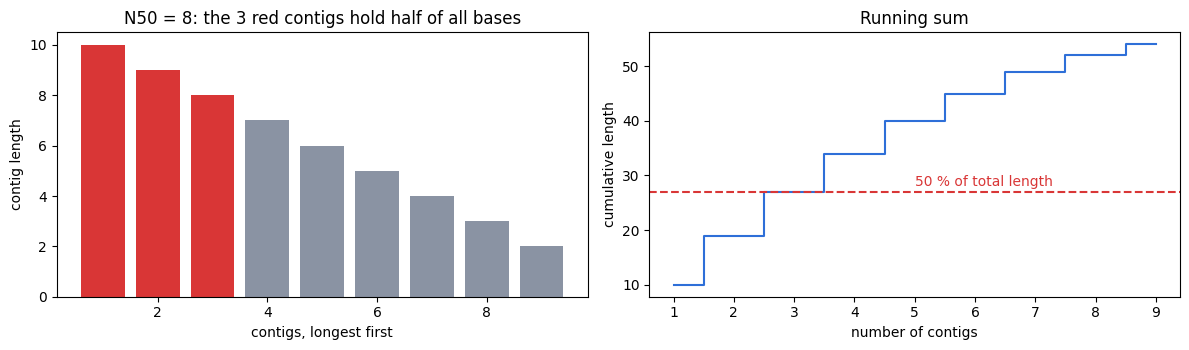

In [ ]:
def nx(lengths, x=50):
    """Return (Nx, Lx) of a list of contig lengths."""
    L = np.sort(np.asarray(lengths))[::-1]
    cum = np.cumsum(L)
    i = np.searchsorted(cum, cum[-1] * x / 100)      # first index where the running sum reaches x %
    return int(L[i]), int(i + 1)

example = [2, 3, 4, 5, 6, 7, 8, 9, 10]
n50, l50 = nx(example)
print(f"example: total = {sum(example)}, N50 = {n50}, L50 = {l50}")

L = sorted(example, reverse=True); cum = np.cumsum(L)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(range(1, len(L) + 1), L, color=["#D93636" if i < l50 else "#8A93A3" for i in range(len(L))])
ax[0].set_xlabel("contigs, longest first"); ax[0].set_ylabel("contig length"); ax[0].set_title(f"N50 = {n50}: the {l50} red contigs hold half of all bases")
ax[1].step(range(1, len(L) + 1), cum, where="mid", color="#2E6FD8")
ax[1].axhline(sum(L) / 2, ls="--", color="#D93636"); ax[1].text(5, sum(L) / 2 + 1, "50 % of total length", color="#D93636")
ax[1].set_xlabel("number of contigs"); ax[1].set_ylabel("cumulative length"); ax[1].set_title("Running sum")
plt.tight_layout(); plt.show()

### 3.2 Statistics of our assembly with calN50

`k8-x86_64-Linux calN50.js <contigs.fa>` reads the FASTA file and prints the total length, the number of contigs and the Nx/Lx values for several x (N10 … N90). We save the result to `09_ASSEMBLY_QC/assemstats.txt`.

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}"
$TOOLS/k8-1.2/k8-x86_64-Linux $TOOLS/calN50.js 08_ASSEMBLY/final.contigs.fa > 09_ASSEMBLY_QC/assemstats.txt
cat 09_ASSEMBLY_QC/assemstats.txt

CC	GS   genome_size_if_provided
CC	SZ   total_sequence_length
CC	NN   number_of_sequences
CC	NL   x   Nx   Lx
CC	AU   auN
CC
SZ	6393053
NN	21686
NL	0	1779	1
NL	10	618	847
NL	20	496	2017
NL	30	419	3426
NL	40	360	5076
NL	50	314	6984
NL	60	276	9157
NL	70	241	11639
NL	80	209	14489
NL	90	179	17793
NL	100	136	21686
AU	364


Let's check calN50 against our own function and look at the contig lengths. We read the contig sequences with a few lines of Python: a line starting with `>` starts a new contig, all other lines are added to the current sequence.

,sample10 assembly
contigs,21686.0
total length (bp),6393053.0
longest (bp),1779.0
shortest (bp),136.0
mean length (bp),294.8
N50 (bp),314.0
L50,6984.0
N90 (bp),179.0
mean GC (%),50.0


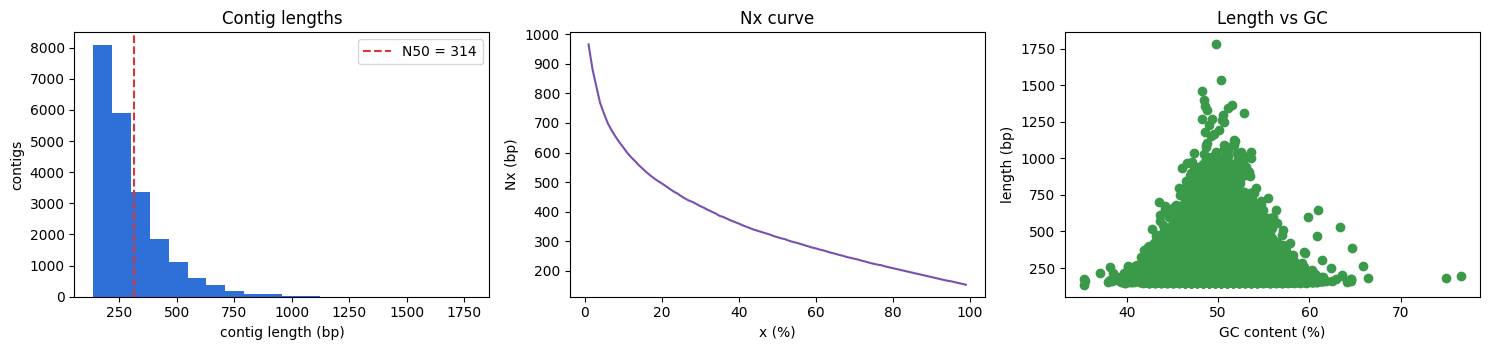

In [ ]:
def read_fasta(path):
    seqs, name = {}, None
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            name = line[1:].split()[0]; seqs[name] = []
        elif name:
            seqs[name].append(line)
    return {k: "".join(v) for k, v in seqs.items()}

contigs = read_fasta("08_ASSEMBLY/final.contigs.fa")
lengths = np.array([len(s) for s in contigs.values()])
gc = np.array([(s.count("G") + s.count("C")) / len(s) for s in contigs.values()])
n50, l50 = nx(lengths)
stats = pd.Series({"contigs": len(lengths), "total length (bp)": lengths.sum(),
                   "longest (bp)": lengths.max(), "shortest (bp)": lengths.min(),
                   "mean length (bp)": round(lengths.mean(), 1), "N50 (bp)": n50, "L50": l50,
                   "N90 (bp)": nx(lengths, 90)[0], "mean GC (%)": round(100 * gc.mean(), 1)})
display(stats.to_frame("sample10 assembly"))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(lengths, bins=20, color="#2E6FD8"); ax[0].axvline(n50, color="#D93636", ls="--", label=f"N50 = {n50}")
ax[0].set_xlabel("contig length (bp)"); ax[0].set_ylabel("contigs"); ax[0].legend(); ax[0].set_title("Contig lengths")
xs = np.arange(1, 100); ax[1].plot(xs, [nx(lengths, x)[0] for x in xs], color="#7B4FB0")
ax[1].set_xlabel("x (%)"); ax[1].set_ylabel("Nx (bp)"); ax[1].set_title("Nx curve")
ax[2].scatter(100 * gc, lengths, color="#3A9A4A"); ax[2].set_xlabel("GC content (%)"); ax[2].set_ylabel("length (bp)")
ax[2].set_title("Length vs GC")
plt.tight_layout(); plt.show()

In the course run, the assembly of sample10 gave **11 contigs** with a total length of **1,465 bp**, **N50 = 136 bp** and **L50 = 5**: five contigs of at least 136 bp make up half of the assembled length. Your numbers may differ slightly with another MEGAHIT version.

The **Nx curve** shows Nx for every x from 1 to 99 %, i.e. the whole length distribution rather than a single number. The **GC content** can help to separate contigs from different organisms, which have characteristic GC contents – the basis of *binning* contigs into genomes.

❓ **Questions**
1. Do calN50 and our function agree?
2. Why is N50 alone a poor measure of assembly quality? (Hint: what happens to N50 if you raise `--min-contig-len` to 500?)
3. How do these contig lengths compare with the length of a bacterial genome (~2–6 Mbp)?

### 3.3 Experiment: k-mer sizes for short ancient reads

MEGAHIT's default k-list goes up to 141, but our reads are mostly shorter than 70 bp, so the large k values contribute nothing. Let's assemble again with **only small k-mers**: `--k-list 15,21,27,31` (k must be odd, between 15 and 255). Smaller k can connect reads with shorter overlaps – but also creates more ambiguous, branching graphs.

In [ ]:
%%bash
cd "${WORKDIR:?WORKDIR is not set - run cell 1.5 first}"
if [ ! -f 08_ASSEMBLY_smallk/final.contigs.fa ]; then
    rm -rf 08_ASSEMBLY_smallk /content/megahit_smallk
    megahit -r 04_HOST_REMOVAL/sample10_unaligned_to_hg38.fastq.gz --out-dir /content/megahit_smallk \
            --k-list 15,21,27,31 --min-contig-len 100 -t $THREADS > /content/megahit_smallk.log 2>&1
    tail -n 5 /content/megahit_smallk.log
    mkdir -p 08_ASSEMBLY_smallk
    cp /content/megahit_smallk/final.contigs.fa /content/megahit_smallk/log 08_ASSEMBLY_smallk/
fi
tail -n 3 08_ASSEMBLY_smallk/log

2026-11-23 12:57:09 - Build graph for k = 31 
2026-11-23 12:57:13 - Assemble contigs from SdBG for k = 31
2026-11-23 12:57:36 - Merging to output final contigs 
2026-11-23 12:57:36 - 29676 contigs, total 7945360 bp, min 100 bp, max 1946 bp, avg 267 bp, N50 316 bp
2026-11-23 12:57:36 - ALL DONE. Time elapsed: 184.148881 seconds 
2026-11-23 12:57:36 - Merging to output final contigs 
2026-11-23 12:57:36 - 29676 contigs, total 7945360 bp, min 100 bp, max 1946 bp, avg 267 bp, N50 316 bp
2026-11-23 12:57:36 - ALL DONE. Time elapsed: 184.148881 seconds 


In [ ]:
rows = {}
for label, path in [("default k (21–141)", "08_ASSEMBLY/final.contigs.fa"),
                    ("small k (15–31)", "08_ASSEMBLY_smallk/final.contigs.fa")]:
    Ls = np.array([len(s) for s in read_fasta(path).values()])
    if len(Ls) == 0:
        rows[label] = {"contigs": 0}; continue
    rows[label] = {"contigs": len(Ls), "total (bp)": Ls.sum(), "longest (bp)": Ls.max(),
                   "N50 (bp)": nx(Ls)[0], "L50": nx(Ls)[1]}
pd.DataFrame(rows).T

,contigs,total (bp),longest (bp),N50 (bp),L50
default k (21–141),21686,6393053,1779,314,6984
small k (15–31),29676,7945360,1946,316,8157


❓ Which k-list gives more and longer contigs? Would you trust contigs assembled from 15-mers as much as those from larger k? Why might the answer differ for a deeply sequenced dental calculus sample?

---
## 4. Abundance quantification of assembled contigs

Which contigs are most abundant in the sample? We **align the reads back to the contigs** – exactly as we aligned reads to the *Y. pestis* genome on Day 3, but now the "reference" is our own assembly.

| Command | Meaning |
|---|---|
| `bowtie2-build --large-index 08_ASSEMBLY/final.contigs.fa 08_ASSEMBLY/final.contigs.fa` | index the contigs; index files are written next to the FASTA, with the same prefix |
| `bowtie2 … -U 03_TRIMMED/sample10.trimmed.fastq.gz` | align the **trimmed** reads of sample10 (as in the course text) |
| `samtools view -bS -h -q 1` | BAM output, keep only reads with **MAPQ ≥ 1** (uniquely placed) |
| `samtools view <bam> \| cut -f3` | column 3 of every alignment = the **contig** the read aligned to – one line per read |

We additionally sort and index the BAM (needed for coverage statistics, IGV and pyDamage).

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}"
bowtie2-build --large-index 08_ASSEMBLY/final.contigs.fa 08_ASSEMBLY/final.contigs.fa --threads $THREADS > 09_ASSEMBLY_QC/bowtie2-build.log 2>&1

bowtie2 --large-index -x 08_ASSEMBLY/final.contigs.fa --end-to-end --threads $THREADS --very-sensitive \
        -U 03_TRIMMED/sample10.trimmed.fastq.gz 2> 09_ASSEMBLY_QC/bowtie2.log \
  | samtools view -bS -h -q 1 -@ $THREADS - > 09_ASSEMBLY_QC/aligned_to_assembled_contigs.bam

samtools view 09_ASSEMBLY_QC/aligned_to_assembled_contigs.bam | cut -f3 > 09_ASSEMBLY_QC/contig_count.txt

samtools sort -@ $THREADS -o 09_ASSEMBLY_QC/aligned_to_assembled_contigs.sorted.bam 09_ASSEMBLY_QC/aligned_to_assembled_contigs.bam
samtools index 09_ASSEMBLY_QC/aligned_to_assembled_contigs.sorted.bam
samtools faidx 08_ASSEMBLY/final.contigs.fa

cat 09_ASSEMBLY_QC/bowtie2.log
echo "reads on contigs (MAPQ >= 1): $(wc -l < 09_ASSEMBLY_QC/contig_count.txt)"

778212 reads; of these:
  778212 (100.00%) were unpaired; of these:
    343213 (44.10%) aligned 0 times
    434998 (55.90%) aligned exactly 1 time
    1 (0.00%) aligned >1 times
55.90% overall alignment rate
reads on contigs (MAPQ >= 1): 425850


[bam_sort_core] merging from 0 files and 2 in-memory blocks...


❓ What fraction of all reads aligns to the assembled contigs? What does this tell you about how much of the sample the assembly represents?

Now let's order the contigs by abundance. The course text does this in R (below, for reference); in Python, `value_counts()` counts how many times each contig name occurs in `contig_count.txt`, i.e. how many reads aligned to it.

<details><summary><b>Original R code (click to expand)</b></summary>

```r
df <- scan("09_ASSEMBLY_QC/contig_count.txt", what = "character")
head(sort(table(df), TRUE))
write.table(data.frame(sort(table(df), TRUE)), file = "09_ASSEMBLY_QC/abund_contigs.txt",
            col.names = FALSE, row.names = TRUE, quote = FALSE, sep = "\t")
```
</details>

In [ ]:
counts = pd.read_csv("09_ASSEMBLY_QC/contig_count.txt", header=None, names=["contig"])["contig"].value_counts()
counts.to_csv("09_ASSEMBLY_QC/abund_contigs.txt", sep="\t", header=False)
print("most abundant contigs:"); print(counts.head(10).to_string())

most abundant contigs:
contig
k59_20406    125
k59_4324     123
k59_20611    104
k59_9646     103
k59_17465    102
k59_1056     102
k59_19493     99
k59_10068     97
k59_18754     96
k59_18178     96


Read counts favour **long** contigs (more places for reads to land). `samtools coverage` gives length-aware numbers per contig: reads, **breadth** (% of the contig covered) and **mean depth**. Mean depth is the fairer measure of abundance.

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}"
samtools coverage 09_ASSEMBLY_QC/aligned_to_assembled_contigs.sorted.bam > 09_ASSEMBLY_QC/contig_coverage.tsv
head -n 5 09_ASSEMBLY_QC/contig_coverage.tsv

#rname	startpos	endpos	numreads	covbases	coverage	meandepth	meanbaseq	meanmapq
k59_0	1	158	8	158	100	2.82278	36.1	42
k59_10843	1	279	20	279	100	4.01434	36.4	41.8
k59_1	1	285	20	285	100	4.19298	36.3	41
k59_10844	1	215	11	207	96.2791	3.22326	36.1	42


,contig,length,numreads,coverage,meandepth,meanmapq
12967,k59_6448,596,85,99.6644,9.95470,41.9
5208,k59_2495,650,88,100.0000,9.52000,41.5
4367,k59_2069,316,61,97.1519,8.50316,40.9
15226,k59_18449,231,31,100.0000,7.90043,40.7
10174,k59_16012,187,21,100.0000,7.80214,40.1
8052,k59_3923,154,16,100.0000,7.38961,42.0
19348,k59_9679,155,16,100.0000,7.25806,40.9
8830,k59_15378,213,25,100.0000,7.23474,40.4
6038,k59_2917,222,24,100.0000,7.17117,41.9
6393,k59_14136,194,27,100.0000,7.09794,41.1


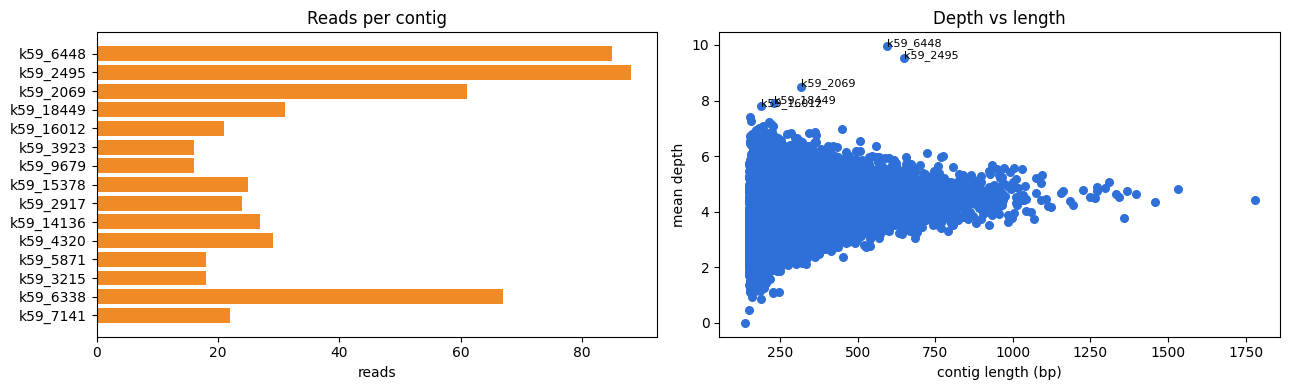

In [ ]:
cov = pd.read_csv("09_ASSEMBLY_QC/contig_coverage.tsv", sep="\t").rename(columns={"#rname": "contig"})
cov["length"] = cov["endpos"]
cov = cov[["contig", "length", "numreads", "coverage", "meandepth", "meanmapq"]].sort_values("meandepth", ascending=False)
display(cov.head(15))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
top = cov.head(15)
ax[0].barh(top.contig, top.numreads, color="#F08A24"); ax[0].invert_yaxis(); ax[0].set_xlabel("reads"); ax[0].set_title("Reads per contig")
ax[1].scatter(cov.length, cov.meandepth, s=30, color="#2E6FD8")
for _, r in top.head(5).iterrows():
    ax[1].annotate(r.contig, (r.length, r.meandepth), fontsize=8)
ax[1].set_xlabel("contig length (bp)"); ax[1].set_ylabel("mean depth"); ax[1].set_title("Depth vs length")
plt.tight_layout(); plt.show()

❓ Can you name a few of the most abundant contigs? Do the rankings by read count and by mean depth agree?

### Look at reads on the contigs in IGV

Our assembly can serve as a reference genome in IGV: `fastaPath`/`indexPath` load the contigs and their `.fai`; the sorted BAM shows the reads. We open the most abundant contig. Are there **C→T mismatches** at read ends? (Careful: the contig sequence was built *from* these reads, so damage can also be "baked into" the contig itself.)

In [ ]:
import igv_notebook
igv_notebook.init()
best = cov.iloc[0]
b = igv_notebook.Browser({
    "reference": {"id": "sample10_contigs", "name": "sample10 contigs",
                  "fastaPath": f"{WORKDIR}/08_ASSEMBLY/final.contigs.fa",
                  "indexPath": f"{WORKDIR}/08_ASSEMBLY/final.contigs.fa.fai"},
    "locus": f"{best.contig}:1-{int(best.length)}"})
b.load_track({"name": "sample10 reads", "path": f"{WORKDIR}/09_ASSEMBLY_QC/aligned_to_assembled_contigs.sorted.bam",
              "indexPath": f"{WORKDIR}/09_ASSEMBLY_QC/aligned_to_assembled_contigs.sorted.bam.bai",
              "format": "bam", "type": "alignment"})
print("showing", best.contig)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

showing k59_6448


---
## 5. Taxonomic annotation of assembled contigs

Which organisms do the contigs come from? We classify each **contig** with **Kraken2** against the MiniKraken2 database (Day 2) – a contig is classified exactly like a read, just with many more k-mers.

| Flag | Meaning |
|---|---|
| `--db $KRAKEN2_DB` | MiniKraken2 database |
| `--output` | one line per **contig**: classified/unclassified, contig name, taxon, length, k-mer hits |
| `--use-names` | write taxon names, not only taxonomy IDs |
| `--report` | per-taxon summary report |
| last argument | the contigs, `08_ASSEMBLY/final.contigs.fa` |

> 📝 The course text has `06_ASSEMBLY/final.contigs.fa` as input here; the assembly is in `08_ASSEMBLY`.

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}"
kraken2 --db $KRAKEN2_DB --threads $THREADS \
        --output 09_ASSEMBLY_QC/sequences.kraken_contigs --use-names \
        --report 09_ASSEMBLY_QC/kraken.output_contigs 08_ASSEMBLY/final.contigs.fa
echo; head -n 5 09_ASSEMBLY_QC/sequences.kraken_contigs | cut -c 1-150


U	k59_0	unclassified (taxid 0)	158	0:124
U	k59_10843	unclassified (taxid 0)	279	0:245
U	k59_1	unclassified (taxid 0)	285	0:251
U	k59_10844	unclassified (taxid 0)	215	0:181
U	k59_2	unclassified (taxid 0)	231	0:197


Loading database information... done.
21686 sequences (6.39 Mbp) processed in 0.461s (2822.9 Kseq/m, 832.20 Mbp/m).
  41 sequences classified (0.19%)
  21645 sequences unclassified (99.81%)


In [ ]:
kc = pd.read_csv("09_ASSEMBLY_QC/sequences.kraken_contigs", sep="\t", header=None,
                 names=["status", "contig", "taxon", "length", "kmer_hits"])
annot = cov.merge(kc[["contig", "status", "taxon"]], on="contig", how="left")
print(f"classified contigs: {(kc.status == 'C').sum()} of {len(kc)}")
display(annot[["contig", "length", "numreads", "meandepth", "status", "taxon"]].head(20))

rep = pd.read_csv("09_ASSEMBLY_QC/kraken.output_contigs", sep="\t", header=None,
                  names=["pct", "clade", "direct", "rank", "taxid", "name"])
rep["name"] = rep["name"].str.strip()
print("\nspecies and genera assigned to contigs:")
display(rep[rep["rank"].isin(["S", "G"]) & (rep.direct > 0)][["rank", "name", "direct"]])

classified contigs: 41 of 21686


,contig,length,numreads,meandepth,status,taxon
0,k59_6448,596,85,9.95470,C,pseudomallei group (taxid 111527)
1,k59_2495,650,88,9.52000,C,pseudomallei group (taxid 111527)
2,k59_2069,316,61,8.50316,C,Enterobacterales (taxid 91347)
3,k59_18449,231,31,7.90043,U,unclassified (taxid 0)
4,k59_16012,187,21,7.80214,U,unclassified (taxid 0)
5,k59_3923,154,16,7.38961,U,unclassified (taxid 0)
6,k59_9679,155,16,7.25806,U,unclassified (taxid 0)
7,k59_15378,213,25,7.23474,U,unclassified (taxid 0)
8,k59_2917,222,24,7.17117,U,unclassified (taxid 0)
9,k59_14136,194,27,7.09794,U,unclassified (taxid 0)



species and genera assigned to contigs:


,rank,name,direct
8,G,Pseudomonas,2
9,S,Pseudomonas psychrophila,12
10,S,Pseudomonas thivervalensis,2
20,S,Burkholderia mallei,1
21,S,Burkholderia thailandensis,1
28,S,Rhodococcus hoagii,2
32,S,Micromonospora echinospora,1


### Compare with read-based profiling

How does the contig-based picture compare with the read-based KrakenUniq profile of sample10 from Day 2 (species passing ≥ 200 reads and ≥ 1000 unique k-mers)?

In [ ]:
ku_file = "05_TAXONOMIC_PROFILE/sample10.krakenuniq.output"
if os.path.exists(ku_file):
    ku = pd.read_csv(ku_file, sep="\t", comment="#")
    ku["taxName"] = ku["taxName"].str.strip()
    ku_sp = ku[(ku["rank"] == "species") & (ku.taxReads >= 200) & (ku.kmers >= 1000)].sort_values("taxReads", ascending=False)
    display(ku_sp[["taxName", "taxReads", "kmers"]].head(15))
    contig_taxa = set(kc.taxon.str.replace(r" \(taxid \d+\)", "", regex=True))
    contig_genera = {t.split()[0] for t in contig_taxa}
    print("read-based species whose genus is also found among contig annotations:")
    print(sorted(s for s in ku_sp.taxName if s.split()[0] in contig_genera))
else:
    print("Day 2 KrakenUniq output not found – run Day2_TaxonomicProfiling.ipynb to compare.")

,taxName,taxReads,kmers
10,Yersinia pestis,11553,164882
175,Burkholderia pseudomallei,7310,267081
29,Salmonella enterica,2560,49800
322,Streptococcus pyogenes,1763,26882
189,Ralstonia solanacearum,749,36158
77,Pseudomonas chlororaphis,294,5727


read-based species whose genus is also found among contig annotations:
['Burkholderia pseudomallei', 'Pseudomonas chlororaphis', 'Yersinia pestis']


❓ **Questions**
1. What fraction of the contigs could be classified? What could the unclassified contigs be?
2. Which organisms are represented by contigs? Are they the most abundant organisms of the read-based profile?
3. Is *Yersinia pestis* among the contigs? Why might an organism that is clearly detected with reads (Days 2–3) not be assembled?

---
## 6. Are the contigs ancient? pyDamage

On Day 3 we tested damage on **one** reference genome. With assembly there can be hundreds of thousands of contigs, and running mapDamage or PMDtools on each would be impractical – and their plots give no yes/no answer per contig. [**pyDamage**](https://doi.org/10.7717/peerj.11845) was designed for exactly this: for every contig it fits a **null model** (no damage) and a **damage model** (C→T decaying from the 5′ end) to the reads aligned to it, and tests with a likelihood-ratio test whether damage explains the data better.

* `pydamage analyze` – analyse all contigs in a **sorted, indexed** BAM of reads aligned to contigs,
* `-w 30` – window: the first 30 positions from the 5′ end are used for the fit,
* `-p $THREADS` – number of processes,
* `MPLBACKEND=Agg PYTHONWARNINGS=ignore` – the plotting-backend fix and warning filter from Day 3.

Results go to `pydamage_results/pydamage_results.csv`: per contig `predicted_accuracy` (how reliable the call is given the amount of data), `damage_model_pmax` (estimated C→T at the read end), `pvalue`/`qvalue` (damage vs no damage, q = corrected for testing many contigs), `nb_reads_aligned`, `coverage`.

In [ ]:
%%bash
cd "${WORKDIR:?run cell 1.5 first}/09_ASSEMBLY_QC"
export MPLBACKEND=Agg PYTHONWARNINGS=ignore
PATH=$ENVS/pydamage/bin:$PATH pydamage analyze -w 30 -p $THREADS aligned_to_assembled_contigs.sorted.bam
ls pydamage_results

pydamage_results.csv


Estimating and testing Damage: 100%|██████████| 21685/21685 [28:28<00:00, 12.69it/s]
21685 contig(s) analyzed by Pydamage


,reference,nb_reads_aligned,coverage,predicted_accuracy,damage_model_pmax,qvalue
18,k59_9816,19,5.776,1.0,0.667,0.001
43,k59_2794,19,4.490,1.0,0.750,0.002
42,k59_17953,11,3.429,1.0,0.788,0.002
38,k59_13921,23,3.882,1.0,0.750,0.002
6080,k59_19180,11,2.953,1.0,0.500,0.320
4935,k59_1775,7,2.620,1.0,0.990,0.189
979,k59_7047,9,3.438,1.0,0.990,0.039
945,k59_6494,13,3.478,1.0,0.674,0.038
2956,k59_646,14,4.412,1.0,0.990,0.142
2948,k59_7325,10,3.190,1.0,0.500,0.142


contigs with significant damage (q < 0.05) and predicted accuracy ≥ 0.5: 1193 of 21685


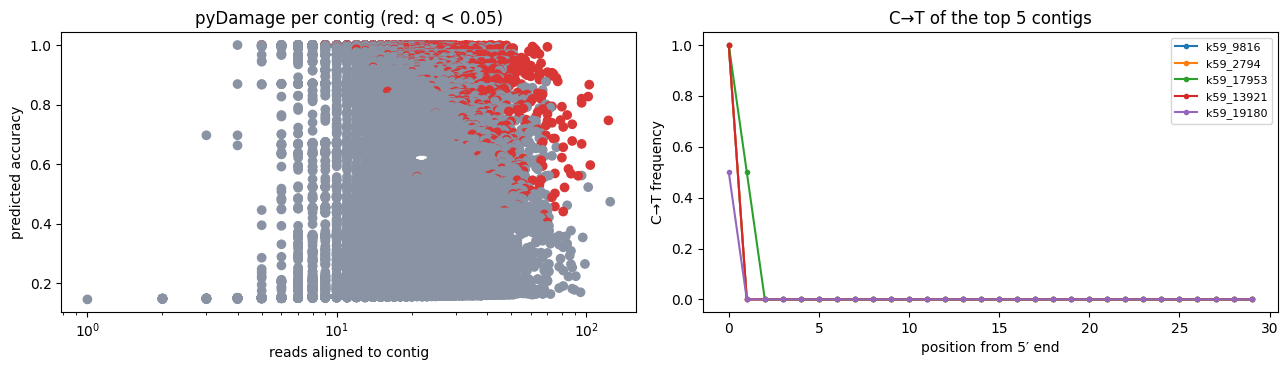

In [ ]:
pyd = pd.read_csv("09_ASSEMBLY_QC/pydamage_results/pydamage_results.csv")
cols = [c for c in ["reference", "nb_reads_aligned", "coverage", "predicted_accuracy",
                    "damage_model_pmax", "qvalue"] if c in pyd.columns]
pyd = pyd.sort_values("predicted_accuracy", ascending=False)
display(pyd[cols].head(15))

ancient = pyd[(pyd.predicted_accuracy >= 0.5) & (pyd.qvalue < 0.05)]
print(f"contigs with significant damage (q < 0.05) and predicted accuracy ≥ 0.5: {len(ancient)} of {len(pyd)}")

ctc = [c for c in pyd.columns if c.startswith("CtoT-")]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].scatter(pyd.nb_reads_aligned, pyd.predicted_accuracy, c=np.where(pyd.qvalue < 0.05, "#D93636", "#8A93A3"))
ax[0].set_xscale("log"); ax[0].set_xlabel("reads aligned to contig"); ax[0].set_ylabel("predicted accuracy")
ax[0].set_title("pyDamage per contig (red: q < 0.05)")
for _, r in pyd.head(5).iterrows():
    ax[1].plot(range(len(ctc)), r[ctc].values, "-o", ms=3, label=r.reference)
ax[1].set_xlabel("position from 5′ end"); ax[1].set_ylabel("C→T frequency"); ax[1].set_title("C→T of the top 5 contigs"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The **predicted accuracy** rises with the number of reads: with only a handful of reads per contig, pyDamage cannot decide either way – a typical situation for low-coverage ancient assemblies.

### All evidence in one table

Finally, everything we know about each contig: length, abundance, taxonomy and damage.

In [ ]:
p2 = pyd[cols].rename(columns={"reference": "contig"})
summary = annot.merge(p2, on="contig", how="left", suffixes=("", "_pyd"))
show = [c for c in ["contig", "length", "numreads", "meandepth", "taxon", "predicted_accuracy",
                    "damage_model_pmax", "qvalue"] if c in summary.columns]
summary[show].to_csv("09_ASSEMBLY_QC/contig_summary.tsv", sep="\t", index=False)
summary[show].head(20)

,contig,length,numreads,meandepth,taxon,predicted_accuracy,damage_model_pmax,qvalue
0,k59_6448,596,85,9.95470,pseudomallei group (taxid 111527),0.223,0.012,1.000
1,k59_2495,650,88,9.52000,pseudomallei group (taxid 111527),0.182,0.000,1.000
2,k59_2069,316,61,8.50316,Enterobacterales (taxid 91347),0.995,0.333,0.010
3,k59_18449,231,31,7.90043,unclassified (taxid 0),0.617,0.100,0.549
4,k59_16012,187,21,7.80214,unclassified (taxid 0),0.429,0.063,0.199
5,k59_3923,154,16,7.38961,unclassified (taxid 0),0.240,0.021,1.000
6,k59_9679,155,16,7.25806,unclassified (taxid 0),0.170,0.000,1.000
7,k59_15378,213,25,7.23474,unclassified (taxid 0),0.170,0.000,1.000
8,k59_2917,222,24,7.17117,unclassified (taxid 0),0.695,0.118,0.456
9,k59_14136,194,27,7.09794,unclassified (taxid 0),0.861,0.167,0.467


❓ Which contigs would you call **ancient**, and which organisms do they belong to? What additional evidence would you collect before publishing a contig as ancient (think of Days 3 and 4)?

---
## Summary

* **De-novo assembly** reconstructs contigs without a reference, using **de Bruijn graphs** of k-mers; it can reveal organisms that are missing from databases.
* Ancient DNA is hard to assemble: **short, damaged reads at low coverage** give few and short contigs; small k-mers help to connect short reads but increase ambiguity.
* **N50/L50** summarise contig lengths, but always look at the whole distribution (Nx curve) and at what the contigs represent.
* **Aligning reads back** to contigs measures their abundance and coverage; **Kraken2** annotates contigs taxonomically; **pyDamage** tests each contig for ancient damage – together they turn contigs into authenticated ancient sequences.

## Questions to think about
1. When would you choose assembly over read-based profiling for an ancient sample, and vice versa?
2. Why is the N50 of an ancient metagenome assembly usually much lower than that of a modern one?
3. How would you go from contigs to **genomes** (metagenome-assembled genomes, MAGs)? (Hint: binning by coverage and GC/k-mer composition.)
4. Could damage be "baked into" assembled contigs, and how would that affect damage estimates?

## Resources
* MEGAHIT: Li D. et al. (2015) *Bioinformatics* 31:1674–1676, [doi:10.1093/bioinformatics/btv033](https://doi.org/10.1093/bioinformatics/btv033) · [usage](https://github.com/voutcn/megahit?tab=readme-ov-file#usage)
* metaSPAdes: Nurk S. et al. (2017) *Genome Research* 27:824–834
* calN50: [github.com/lh3/calN50](https://github.com/lh3/calN50) · k8: [github.com/attractivechaos/k8](https://github.com/attractivechaos/k8)
* pyDamage: Borry M. et al. (2021) *PeerJ* 9:e11845, [doi:10.7717/peerj.11845](https://doi.org/10.7717/peerj.11845)
* Kraken2: Wood D.E. et al. (2019) *Genome Biology* 20:257
* For ancient metagenome assembly in practice, see e.g. the nf-core/mag pipeline, which includes aDNA-specific options (damage-aware consensus, pyDamage).

In [30]:
!jupyter nbconvert --to html /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_Assembly.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_Assembly.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 3290743 bytes to /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_Assembly.html
